In [209]:
import pandas as pd
import numpy as np
import seaborn as sns

In [210]:
df = pd.read_csv("data.csv")

In [211]:
string_columns = df.select_dtypes(include=["object", "string"]).columns
df[string_columns] = df[string_columns].apply(lambda col: col.str.lower().str.replace(" ", "_"))

df.columns = df.columns.str.lower().str.replace(" ", "_")

In [212]:
df["log_msrp"] = np.log1p(df.msrp)

In [213]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

In [214]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.4, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


print(f"train: {len(train_df)} ({len(train_df) / len(df):.0%})")
print(f"val:   {len(val_df)} ({len(val_df) / len(df):.0%})")
print(f"test:  {len(test_df)} ({len(test_df) / len(df):.0%})")

train: 7148 (60%)
val:   2383 (20%)
test:  2383 (20%)


<Axes: xlabel='log_msrp', ylabel='Count'>

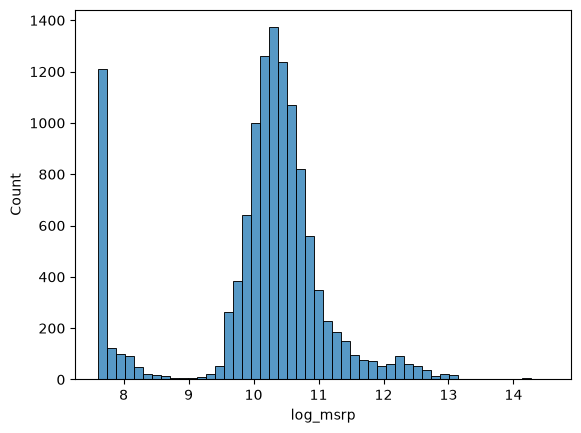

In [215]:
sns.histplot(df.log_msrp, bins=50)

In [216]:
y_train = np.log1p(train_df.msrp.values)
y_val = np.log1p(val_df.msrp.values)
y_test = np.log1p(test_df.msrp.values)


In [217]:
base = ["engine_hp", "engine_cylinders", "highway_mpg", "city_mpg", "popularity"]


# Fixed make categories from training data; drop first as reference to avoid the dummy-variable trap.df.head().columns


categories = [col for col, dtype in df.dtypes.items() if dtype == 'str']


In [218]:
X_train = train_df[base].values
X_train = train_df[base].fillna(0).values


In [219]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    """
     First we transpose. Rows become columns and cols become rows.
     Then we multiply the new matrix with original
     Multiplication example:
    Example:

    A (2*3):
    A = [1 2 3]
        [4 5 6]
        
    B (3*2):
    B = [ 7  8]
        [ 9 10]
        [11 12]
    Result C = A·B will be (2*2).

    C[0][0] = (1·7) + (2·9) + (3·11) = 7 + 18 + 33 = 58
    C[0][1] = (1·8) + (2·10) + (3·12) = 8 + 20 + 36 = 64
    C[1][0] = (4·7) + (5·9) + (6·11) = 28 + 45 + 66 = 139
    C[1][1] = (4·8) + (5·10) + (6·12) = 32 + 50 + 72 = 154

    C = [ 58  64]
        [139 154]
    """
    XTX = X.T.dot(X)

    # There is no division in general. There is only multiplication with
    # the numbers inverse: 4 / 2 == 4 * 2 ** (-1)

    # The magic formula called the normal equation:
    # X^T X w = X^T y

    # Also, it's a coincidence that X^T for matrixes X.T also creates a
    # square matrix for which we have a inverse (or maybe not a surprise)

    # To isolate w, you multiply both sides on the left by (X^T X)^{-1}:
    # (X^T X)^{-1} (X^T X) w = (X^T X)^{-1} X^T y
    # w = (X^T X)^{-1} X^T y

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


# train_df.T.dot(train_df)


def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    # Ridge: add r to the diagonal so XTX stays well-conditioned and invertible.
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [220]:
w0, w = train_linear_regression(X_train, y_train)

In [221]:
y_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

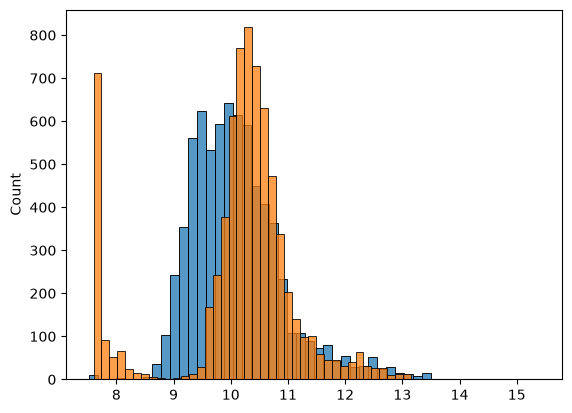

In [222]:
sns.histplot(y_pred, bins=50)
sns.histplot(y_train, bins=50)


In [223]:
def rmse(y_pred, y):
    error = y - y_pred
    se = error**2
    mse = se.mean()
    return np.sqrt(mse)

In [224]:
rmse(y_train, y_pred)

np.float64(0.7537886298959052)

In [228]:
def prepare_X(df, base=base):
    df = df.copy()

    df["age"] = 2017 - df.year

    features = base.copy()
    features.append("age")

    categories = [col for col, dtype in df.dtypes.items() if dtype == 'str']

    new_columns = {}
    for category in categories:
        unique_category_values = sorted(train_df[category].dropna().unique())[1:]

        for val in unique_category_values:
            name = f"{category}_{val}"
            new_columns[name] = (df[category] == val).astype("int")
            features.append(name)

    df = pd.concat([df, pd.DataFrame(new_columns, index=df.index)], axis=1)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values

    return X


In [229]:
X_train = prepare_X(train_df)
X_val = prepare_X(val_df)

for r in [0, 0.000001, 0.0001, 0.001, 0.01, 0.1, 1, 10]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    print(f"r={r:<10} rmse={rmse(y_val, y_pred):.4f}")

r=0          rmse=968009721401381120.0000
r=1e-06      rmse=0.4581
r=0.0001     rmse=0.2032
r=0.001      rmse=0.2028
r=0.01       rmse=0.2000
r=0.1        rmse=0.1979
r=1          rmse=0.2173
r=10         rmse=0.3272


In [227]:
list(df.make.value_counts().head().index)

['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']